# 03 NH투자증권(2018) 퀄리티·로우볼 팩터 재현

## 0. 원문 정리
원문: NH투자증권 하재석·박소현(2018-10-18), 「Korea Factor Investing 시리즈(2): 버핏의 알파, 퀄리티와 로우볼」. 퀄리티 시험 조건(p.18), 로우볼 시험 조건(p.23), 리밸런싱 주기(p.21·26).

| 항목 | 원문 | 쪽 | 우리 설정 |
|---|---|---|---|
| 유니버스 | KOSPI 상장종목 중 관리종목·거래정지 아닌 종목, 리밸런싱 당일 상장 종목 | 18, 23 | `시장=["KS"]`, 거래정지(CP10001650)·관리종목(CP10001660) 제외 |
| 퀄리티 지표 | ROE, 영업이익률, 부채비율, 총자산회전율 | 18 | `ROE`·`영업이익률`·`부채비율`(낮게)·`총자산회전율` |
| 로우볼 지표 | 일간수익률의 12개월 변동성 하위 | 23 | `변동성`(직전 12개월 일간수익률 표준편차, 낮게). 원문에 최소 관측 기준이 없어 **직전 12개월 내내 시장구분이 코스피·코스닥인 종목만**. 기간 안 빈칸은 빼고 계산 |
| 묶음 | 1~5분위 동일가중 | 18 | `고르기=("분위",5)`, `비중=["동일"]` |
| 리밸런싱 | 3개월 단위 월말 | 18, 23 | `기준일="마지막거래일"`, `리밸런싱=3` |
| 재무 반영 | 분기/연간 재무제표가 발표되는 월의 월말 | 18 | `재무시점=("발표일",150)`: 실적보고서발표일(FP56000900) 다음 거래일부터, 발표일이 없으면 결산일 + 150일(확인판 180일). 근거 = 02 노트북 발표 지연 통계. **연간만**(분기 없음) |
| 기간 | 2002-03 ~ 2018-09 | 18, 23 | 원문 기간 = `("2002-03","2018-09")` |
| 원문 결과(문장) | 4개 지표 모두 2~4분위 누적수익률이 가장 높음, 5분위(로우퀄리티)는 현저히 낮음 | 18 | 아래 8절에서 같은 방향인지 판정 |
| 원문 결과(문장) | 로우볼 LS 프리미엄 존재 | 23 | LS = Q1(저변동) − Q5 |
| 원문 결과(문장) | 퀄리티: 3개월·6개월 리밸런싱 차이 미미(총자산회전율, 그림 29) / 로우볼: 6·12개월이 3개월보다 누적 우수(그림 37) | 21, 26 | 리밸런싱 3·6·12 비교 |

줄임말: EW(동일가중, Equal Weight), VW(시가총액가중, Value Weight), LS(롱숏: 좋은 분위를 사고 나쁜 분위를 판 수익률),
MDD(최대 낙폭, Maximum Drawdown), IR(정보비율, Information Ratio), CAPM(자본자산가격결정모형), FF3(파마-프렌치 3요인), Carhart(카하트 4요인: FF3 + 모멘텀),
OLS(보통최소제곱), NW(뉴이-웨스트: 자기상관·이분산을 감안한 t), TR(배당 포함 수정주가).

## 1. 불러오기
계산은 모두 `공통/` 폴더의 모듈이 한다. 이 노트북은 설정을 정하고, 실행하고, 결과를 본다.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "공통"))
import pandas as pd
import 데이터읽기 as 읽기, 종목거르기, 지표, 포트폴리오 as 포, 평가
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 300)

## 2. 데이터 경로와 기간
데이터를 어디서 읽을지, 어느 기간을 돌릴지 정한다. 기간은 (첫 리밸런싱 월, 마지막 기준일 월)이다.

In [2]:
# 새로 통째로 받은 파일(읽기.DATA 기본 = data\통합_전체_202611, DataGuide 달력기준 일간)로 원문 기간을 돌린다.
기간 = ("2002-03", "2018-09")
print("데이터:", 읽기.DATA, "/ 기간:", 기간)

데이터: D:\26-2_데이터기반투자전략\과제02\data\통합_202611 / 기간: ('2002-03', '2018-09')


## 3. 설정

In [3]:
기본 = {**포.기본설정, "이름": "NH퀄리티로우볼", "시장": ["KS"], "기간": 기간, "기준일": "마지막거래일", "리밸런싱": 3,
       "재무시점": ("발표일", 150), "제외": [("거래정지", {"아이템": 읽기.정지여부}), "관리종목"],
       "고르기": ("분위", 5), "비중": ["동일"], "거래비용": dict(수수료=0, 거래세=0, 슬리피지=0)}
지표들 = {"ROE": ("ROE", "높게"), "영업이익률": ("영업이익률", "높게"), "부채비율": ("부채비율", "낮게"),
         "총자산회전율": ("총자산회전율", "높게"), "로우볼": ("변동성", "낮게")}
pd.Series(기본).astype(str).to_frame("공통 설정")

,공통 설정
시장,['KS']
가격,S410007700
기간,"('2002-03', '2018-09')"
기준일,마지막거래일
리밸런싱,3
재무시점,"('발표일', 150)"
제외,"[('거래정지', {'아이템': 'CP10001650'}), '관리종목']"
지표,"[('ROC', '높게'), ('EY', '높게')]"
합산,순위합산
고르기,"('분위', 5)"


## 4. 실행: 지표별 5분위

In [4]:
결과 = {n: 포.실행({**기본, "지표": [m]}) for n, m in 지표들.items()}
F = 평가.요인(포.기준일(기본), 기본)
누적 = pd.DataFrame({n: (1 + o["수익률"]["동일"]).prod() - 1 for n, o in 결과.items()}).T
누적

,Q1,Q2,Q3,Q4,Q5
ROE,4.6843,10.1499,9.6505,10.8356,4.7733
영업이익률,6.7469,5.5290,12.5613,10.9990,4.5832
부채비율,7.9137,8.5535,12.0377,9.0722,3.2844
총자산회전율,11.9954,9.6825,8.8042,6.7272,3.7638
로우볼,11.9532,9.3810,10.7316,11.4036,1.5799


## 5. LS(Q1 − Q5) 성과와 그림

,개월,누적,연환산,표준편차(연),샤프,MDD,정보비율,초과평균 α(월),초과평균 t(OLS),초과평균 t(NW),CAPM α(월),CAPM t(OLS),CAPM t(NW),FF3 α(월),FF3 t(OLS),FF3 t(NW),Carhart α(월),Carhart t(OLS),Carhart t(NW)
ROE,198.0000,-0.2526,-0.0175,0.1303,-0.0693,-0.4655,-0.3771,-0.0008,-0.2815,-0.2739,-0.0008,-0.2933,-0.2887,-0.0010,-0.4094,-0.4252,-0.0022,-0.9036,-0.9151
영업이익률,198.0000,-0.1329,-0.0086,0.1657,0.0289,-0.4918,-0.2559,0.0004,0.1173,0.1059,0.0012,0.3774,0.3505,0.0006,0.1971,0.1866,-0.0008,-0.2633,-0.2399
부채비율,198.0000,0.2170,0.0120,0.1610,0.1519,-0.5357,-0.1676,0.0020,0.6170,0.6238,0.0039,1.4217,1.4604,0.0046,1.6040,1.7275,0.0039,1.3679,1.5169
총자산회전율,198.0000,1.5021,0.0572,0.1201,0.5288,-0.3604,-0.0586,0.0053,2.1481,2.0491,0.0050,2.0384,1.9941,0.0048,1.8675,1.9963,0.0043,1.6272,1.8296
로우볼,198.0000,1.1050,0.0461,0.2079,0.3246,-0.5311,-0.0248,0.0056,1.3187,1.3460,0.0075,1.9560,2.0009,0.0015,0.4509,0.4626,0.0009,0.2765,0.2910


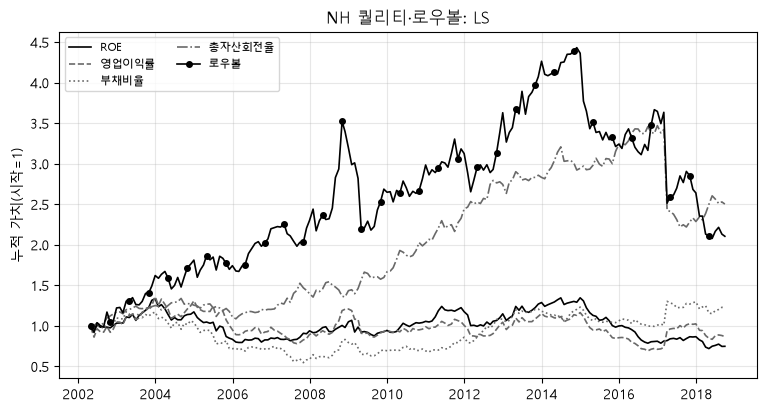

In [5]:
LS = pd.DataFrame({n: o["수익률"]["동일"]["Q1"] - o["수익률"]["동일"]["Q5"] for n, o in 결과.items()})
평가.누적그림(LS, "NH 퀄리티·로우볼: LS");
평가.성과표(LS, F, list(LS))

## 6. 분위별 성과(지표별 Q1~Q5)

In [6]:
평가.성과표(pd.DataFrame({f"{n}_{g}": o["수익률"]["동일"][g] for n, o in 결과.items() for g in o["수익률"]["동일"]}), F)

,개월,누적,연환산,표준편차(연),샤프,MDD,정보비율,초과평균 α(월),초과평균 t(OLS),초과평균 t(NW),CAPM α(월),CAPM t(OLS),CAPM t(NW),FF3 α(월),FF3 t(OLS),FF3 t(NW),Carhart α(월),Carhart t(OLS),Carhart t(NW)
ROE_Q1,198.0000,4.6843,0.1111,0.2137,0.4639,-0.5116,0.5107,0.0083,1.8845,1.6755,0.0044,2.0496,1.9750,0.0027,1.6310,1.8759,0.0022,1.3314,1.4173
ROE_Q2,198.0000,10.1499,0.1574,0.2179,0.6451,-0.4942,0.7281,0.0117,2.6205,2.2484,0.0081,3.0280,3.0420,0.0049,2.1842,2.3881,0.0044,1.9403,2.0878
ROE_Q3,198.0000,9.6505,0.1542,0.1890,0.6991,-0.4086,0.7882,0.0110,2.8397,2.4461,0.0078,3.5695,3.6164,0.0046,3.3307,3.1439,0.0041,2.9677,2.5907
ROE_Q4,198.0000,10.8356,0.1616,0.2279,0.6444,-0.5032,0.7303,0.0123,2.6175,2.2350,0.0085,2.9810,2.8082,0.0047,2.7463,3.0651,0.0046,2.6357,2.8622
ROE_Q5,198.0000,4.7733,0.1121,0.2487,0.4348,-0.6047,0.3735,0.0090,1.7662,1.4936,0.0052,1.5108,1.3851,0.0037,1.7287,1.7174,0.0044,2.0683,2.0604
영업이익률_Q1,198.0000,6.7469,0.1321,0.1839,0.6053,-0.3989,0.5444,0.0093,2.4587,2.1241,0.0063,2.6908,2.6351,0.0046,2.1631,2.2205,0.0041,1.9117,1.9367
영업이익률_Q2,198.0000,5.5290,0.1204,0.2149,0.5019,-0.5200,0.5563,0.0090,2.0388,1.7752,0.0052,2.2602,2.2579,0.0021,1.2215,1.2689,0.0016,0.9335,0.8811
영업이익률_Q3,198.0000,12.5613,0.1712,0.2274,0.6817,-0.4960,0.8745,0.0129,2.7693,2.4261,0.0090,3.4969,3.3563,0.0049,3.1142,3.2856,0.0044,2.8067,2.6634
영업이익률_Q4,198.0000,10.9990,0.1625,0.2279,0.6480,-0.5356,0.7440,0.0123,2.6322,2.2406,0.0085,3.0281,2.8836,0.0050,3.0433,3.5278,0.0046,2.7792,3.1963
영업이익률_Q5,198.0000,4.5832,0.1099,0.2493,0.4273,-0.6124,0.3644,0.0089,1.7357,1.4548,0.0050,1.4676,1.3317,0.0040,1.8393,1.6801,0.0049,2.2766,2.0198


## 7. 리밸런싱 주기 비교 (그림 29·37)
총자산회전율(퀄리티)과 로우볼을 3·6·12개월 리밸런싱으로 다시 돌린다.

In [7]:
주기 = {}
for n in ["총자산회전율", "로우볼"]:
    for k in [3, 6, 12]:
        r = 포.실행({**기본, "지표": [지표들[n]], "리밸런싱": k})["수익률"]["동일"]
        주기[(n, k)] = {"Q1 누적": (1 + r["Q1"]).prod() - 1, "Q5 누적": (1 + r["Q5"]).prod() - 1, "LS 누적": (1 + r["Q1"] - r["Q5"]).prod() - 1}
pd.DataFrame(주기).T

Q1 누적  Q5 누적  LS 누적
총자산회전율 3  11.9954 3.7638 1.5021
       6  11.7326 2.9162 2.1852
       12 10.9642 2.6718 2.2173
로우볼    3  11.9532 1.5799 1.1050
       6  14.6471 0.8380 2.9632
       12 12.9534 0.4399 3.9908

## 8. 원문 vs 우리
원문은 숫자 표 없이 그림과 문장이라, 문장이 우리 결과에서도 성립하는지 참/거짓으로 본다.
확인판 칸은 ROE·부채비율을 자본이 0보다 큰 종목만으로 다시 계산한 것이다(자본이 음수면 ROE·부채비율 부호가 뒤집혀 Q1에 들어감, 11절). 두 칸이 다르면 그 판정은 음수 자본 처리에 따라 바뀌는 경계 결과다.

In [8]:
주기표 = pd.DataFrame(주기).T
판정 = lambda 누적: {"4개 퀄리티 지표 모두 2~4분위 누적이 가장 높음": all(누적.loc[n].idxmax() in ["Q2", "Q3", "Q4"] for n in list(지표들)[:4]),
       "4개 퀄리티 지표 모두 5분위 누적이 가장 낮음": all(누적.loc[n].idxmin() == "Q5" for n in list(지표들)[:4]),
       "로우볼 LS 누적이 양(+)": bool((1 + LS["로우볼"]).prod() - 1 > 0),
       "로우볼: 6·12개월 리밸런싱 LS 누적 > 3개월": bool(min(주기표.loc[("로우볼", 6), "LS 누적"], 주기표.loc[("로우볼", 12), "LS 누적"]) > 주기표.loc[("로우볼", 3), "LS 누적"])}
누적2 = 누적.copy()
for n in ["ROE", "부채비율"]:
    누적2.loc[n] = (1 + 포.실행({**기본, "지표": [(f"{n}_양자본", 지표들[n][1])]})["수익률"]["동일"]).prod() - 1
display((1 + 결과["ROE"]["수익률"]["동일"].loc["2008"]).prod().sub(1).rename("ROE 분위별 2008년 누적").to_frame())
display(pd.concat({"본문": 누적.loc[["ROE", "부채비율"]], "확인판(자본>0만)": 누적2.loc[["ROE", "부채비율"]]}))
판정표 = pd.DataFrame({"우리": 판정(누적), "확인판(자본>0만)": 판정(누적2)}).rename_axis("원문 주장")
판정표.to_csv(평가.결과폴더 / "03_원문판정.csv", encoding="utf-8-sig")  # 결과요약 노트북이 읽음
판정표

,ROE 분위별 2008년 누적
Q1,-0.4098
Q2,-0.3799
Q3,-0.3192
Q4,-0.3913
Q5,-0.4794


Q1      Q2      Q3      Q4     Q5
본문         ROE  4.6843 10.1499  9.6505 10.8356 4.7733
           부채비율 7.9137  8.5535 12.0377  9.0722 3.2844
확인판(자본>0만) ROE  4.9792 10.0047  9.8378 10.8954 4.6889
           부채비율 8.4449  8.6498 12.2753  8.8170 3.2897

,우리,확인판(자본>0만)
원문 주장,,
4개 퀄리티 지표 모두 2~4분위 누적이 가장 높음,False,False
4개 퀄리티 지표 모두 5분위 누적이 가장 낮음,False,True
로우볼 LS 누적이 양(+),True,True
로우볼: 6·12개월 리밸런싱 LS 누적 > 3개월,True,True


## 9. 확인판: 재무시점 180일, 무위험이자율
- **재무시점**: 발표일이 없는 행에 결산일 + 150일 대신 180일을 쓰면 LS 누적이 달라지는지 본다.
- **무위험이자율**: 본문은 콜금리(1일물 중개거래, E11.02.003.001). 1988년부터 빈 달 없이 값이 있는 금리는 이것과 무담보콜금리(1일물 은행간 직거래, E11.02.003.002) 둘이다. 확인판은 무담보콜, 그리고 2000년 이후 기간은 통안채 364일(E11.02.003.009, 1993-07부터 있음. NH 원문 기간이 모두 2000년 이후라 전체 기간에 쓰임). 무위험이자율은 포트폴리오를 바꾸지 않고 샤프·알파만 바꾼다(1분위로 본다).

In [9]:
늦게 = {n: 포.실행({**기본, "지표": [m], "재무시점": ("발표일", 180)}) for n, m in 지표들.items() if n != "로우볼"}
display(pd.DataFrame({"150일(본문)": (1 + LS.drop(columns="로우볼")).prod() - 1, "180일(확인판)": (1 + pd.DataFrame({n: o["수익률"]["동일"]["Q1"] - o["수익률"]["동일"]["Q5"] for n, o in 늦게.items()})).prod() - 1}).rename_axis("LS 누적"))
Q1x = pd.DataFrame({n: o["수익률"]["동일"]["Q1"] for n, o in 결과.items()}).dropna(how="all")
금리 = {"콜(본문)": F, "무담보콜": 평가.요인(포.기준일(기본), {**기본, "무위험": "E11.02.003.002"}),
       "통안364(2000년 이후)": 평가.요인(포.기준일(기본), {**기본, "무위험": "E11.02.003.009"}).loc["2000":]}
pd.concat({k: 평가.성과표(Q1x.loc[f.index[0]:], f)[["샤프", "CAPM α(월)", "Carhart α(월)"]] for k, f in 금리.items()}, axis=1)

,150일(본문),180일(확인판)
LS 누적,,
ROE,-0.2526,-0.2570
영업이익률,-0.1329,-0.1071
부채비율,0.2170,0.1768
총자산회전율,1.5021,1.4741


콜(본문)                          무담보콜                        통안364(2000년 이후)                       
           샤프 CAPM α(월) Carhart α(월)     샤프 CAPM α(월) Carhart α(월)              샤프 CAPM α(월) Carhart α(월)
ROE    0.4639    0.0044       0.0022 0.4644    0.0044       0.0022          0.4449    0.0044       0.0022
영업이익률  0.6053    0.0063       0.0041 0.6059    0.0063       0.0041          0.5830    0.0062       0.0040
부채비율   0.6755    0.0072       0.0048 0.6761    0.0072       0.0048          0.6520    0.0071       0.0047
총자산회전율 0.6879    0.0088       0.0063 0.6884    0.0088       0.0063          0.6693    0.0088       0.0063
로우볼    0.9385    0.0091       0.0043 0.9392    0.0091       0.0043          0.9100    0.0090       0.0042

## 10. 확인: 리밸런싱마다 종목 수·빈칸으로 빠진 수

In [10]:
pd.concat({n: o["기록"] for n, o in 결과.items()}, axis=1).T

기준일               2002-03-29  2002-06-28  2002-09-30  2002-12-30  2003-03-31  2003-06-30  2003-09-30  2003-12-30  2004-03-31  2004-06-30  2004-09-30  2004-12-30  2005-03-31  2005-06-30  2005-09-30  2005-12-29  \
ROE    가격있음             1451        1464        1496        1512        1541        1530        1547        1557        1570        1552        1555        1570        1583        1557        1585        1619   
       시장                687         671         678         682         684         680         686         683         682         674         676         683         688         680         695         702   
       쓰지말것              687         671         675         681         684         680         685         681         681         673         673         682         685         679         693         701   
       거래정지              657         655         667         670         669         669         675         670         661         664         664         674         667         668         684         693   
       관리종목              571         582         594         605         615         618         624         626         620         622         625         641         653         653         671         681   
       빈칸:ROE             13           7          10          16          10           8          11          11          10          10          11          18          23           7          23          20   
       빈칸으로 빠짐            13           7          10          16          10           8          11          11          10          10          11          18          23           7          23          20   
       편입:Q1             112         115         117         118         121         122         123         123         122         123         123         125         126         130         130         133   
       편입:Q2             111         115         117         118         121         122         122         123         122         122         123         124         126         129         129         132   
       편입:Q3             112         115         116         117         121         122         123         123         122         122         122         125         126         129         130         132   
       편입:Q4             111         115         117         118         121         122         122         123         122         122         123         124         126         129         129         132   
       편입:Q5             112         115         117         118         121         122         123         123         122         123         123         125         126         129         130         132   
       확인:업종빈칸             6           6           7           6           7           7           7           7           6           6           6           6           6           7           9           9   
       확인:WICS금융          55          59          59          58          60          60          60          61          59          59          59          65          73          75          89          91   
영업이익률  가격있음             1451        1464        1496        1512        1541        1530        1547        1557        1570        1552        1555        1570        1583        1557        1585        1619   
       시장                687         671         678         682         684         680         686         683         682         674         676         683         688         680         695         702   
       쓰지말것              687         671         675         681         684         680         685         681         681         673         673         682         685         679         693         701   
       거래정지              657         655         667         670         669         669         675         670         661         664         664         674         667         668

## 11. 차이 이유 후보
- **재무 주기**: 원문은 분기 재무도 발표 월말에 반영한다. 우리는 연간만(받은 재무가 결산 항목뿐).
- **ROE·부채비율 정의**: 원문에 분모(기말/평균, 지배/전체) 정의가 없다. 우리는 ROE = 지배순이익/지배자본(기말), 부채비율 = 부채총계/자본총계.
- **변동성**: 원문은 12개월 일간 변동성. 원문에 최소 관측 기준이 없어 직전 12개월 내내 시장구분이 코스피·코스닥인 종목만 쓴다(코스닥에서 옮겨 온 종목도 코스닥 기간이 이어져 들어감, 코드 재사용 공백이 있으면 빠짐).
- **ROE 2008년 방어 효과(그림 26)**: 그림이라 참/거짓 숫자 기준이 없어 판정하지 않고, 8절의 'ROE 분위별 2008년 누적' 표로만 본다.
- **퀄리티 3·6개월 '차이 미미'(p.21)**: '미미'의 숫자 기준이 원문에 없어 참/거짓으로 판정하지 않고 7절 표(총자산회전율 3·6개월)로만 본다.
- **음수 분모**: ROE·부채비율은 공식 그대로라 자본이 음수인 종목은 ROE·부채비율 부호가 뒤집혀 좋은 쪽에 줄 설 수 있다(값은 고치지 않음).
- **벤치마크**: 시장지수는 코스피 가격지수(I.001, 배당 미포함)인데 포트폴리오는 배당 포함 수정주가(TR)다. 정보비율·CAPM α가 배당수익률만큼 높게 나온다(코스피 TR I.030은 X01에 있지만 원문 벤치마크가 아니라 쓰지 않음). KOSPI 행의 알파·t는 자기 자신 회귀라 뜻이 없다.

## 12. 원문과 다르게 한 것
| 항목 | 원문 | 우리 | 이유 |
|---|---|---|---|
| 재무 | 분기+연간 | 연간만, 발표일 다음 거래일(없으면 결산일 + 150일, 확인판 180일) | 받은 재무가 결산(연간) 항목뿐 |
| 변동성 산출 기간 비교(12·36·60개월, 일·주·월 수익률) | 있음(그림 33·34) | 안 함(1년 일간만) | `지표.변동성` 하나만 만듦. 필요하면 함수 추가 |
| 시총 300위 이내 비교 | 있음(그림 27·35) | 안 함 | 같은 방식으로 `("시총상위", {"n": 300})`을 넣으면 됨 |
| 상장 구간 | 상장 종목 | 시장구분(CP10000300)이 코스피·코스닥('KS'·'KQ')인 날의 가격만 계산에 씀(`읽기.상장가격`). 원본 값은 그대로 | 통합_확인기록 F2(상장일보다 앞선 가격 = 이전상장 전 시장 가격)·F3(상장폐지 뒤 장외 가격). 회원 결정 2026-11-02 |
| '쓰지 말 것' 칸 | — | README_데이터의 '쓰지 말 것' 구간이 [리밸런싱일, 다음 리밸런싱일]에 걸리면 편입 대상에서 뺌(`종목거르기.쓰지말것`, 항상 `시장` 다음 단계). 직전 12개월 일간수익률에서도 빈칸으로 봄. 값은 그대로 | A008080 2004-01~2013-09(D-05, 재조회 R28도 값 같음), 수정주가 병합·감자 미반영 7칸의 그 달(D27), 배당 포함 가격(TR)을 쓸 때 TR 이상칸 107칸의 앞날~그날(D-06·U3). 회원 결정 2026-11-02 |
| 호텔신라(A008770) FY2023 | — | 매출원가·매출총이익을 빈칸으로 봄 → 그해 GP/A 등에서 제외(값은 그대로, `지표.빈칸으로볼칸`) | 판본마다 값이 다름(R29 재조회는 매출원가 0, 10월 파일은 1,418,625,926천원). 통합_확인기록 F1. 회원 결정 2026-11-02 |
| 끝 날짜 | — | 가격·시장 일간 항목(S·CP 파일)에 값이 있는 마지막 날(`읽기.공통끝`)에서 자름. 재무 일간은 끝나지 않은 회계연도가 빈칸이라 판정에서 뺌 | 통합_확인기록 F6(항목마다 끝 날짜가 다를 수 있음) |
| 코드 재사용 16종목 | — | 재사용 경계를 넘는 수익률을 쓰지 않음(공백 구간이 빈칸이라 끊김, 01 노트북 11절에서 확인). 직전 12개월 상장 판정도 시장구분으로 함 | 통합_확인기록 F5, README_데이터 D-04 |
| 재무 값 뽑기 | — | 달력기준 일간 재무에서 결산일(결산월 이력이 그 달인 달의 마지막 영업일) 값을 그 회계연도 값으로 씀(`읽기.연간재무`). 쓸 수 있는 날은 재무시점 규칙 | 일간 값은 발표 전부터 그 회계연도 값이 들어 있어 그대로 쓰면 미래 정보. 예전 연간 원본과 자산총계 79,657/79,837행 같음(`_검증/일간재무_대조_결과.txt`) |
| 같은 회계연도 두 결산월 | — | 결산일이 늦은 행 | 통합_확인기록 F9(A432320) |
| TR 이상칸 | — | 위 '쓰지 말 것' 칸 중 TR 이상칸이 이 노트북에 해당(배당 포함 가격을 씀) | README_데이터 D-06·U3 |


## 13. 요약표용 저장
지표별 Q1과 LS의 월수익률을 `결과_월수익률/`에 남긴다.

In [11]:
S = pd.DataFrame({(f"NH퀄리티로우볼 {n} Q1", "동일"): o["수익률"]["동일"]["Q1"] for n, o in 결과.items()} | {(f"NH퀄리티로우볼 {n} LS", "동일"): LS[n] for n in LS})
평가.저장(S, F, "03_NH퀄리티로우볼", [k for k in S if k[0].endswith(" LS")])
list(S)

[('NH퀄리티로우볼 ROE Q1', '동일'),
 ('NH퀄리티로우볼 영업이익률 Q1', '동일'),
 ('NH퀄리티로우볼 부채비율 Q1', '동일'),
 ('NH퀄리티로우볼 총자산회전율 Q1', '동일'),
 ('NH퀄리티로우볼 로우볼 Q1', '동일'),
 ('NH퀄리티로우볼 ROE LS', '동일'),
 ('NH퀄리티로우볼 영업이익률 LS', '동일'),
 ('NH퀄리티로우볼 부채비율 LS', '동일'),
 ('NH퀄리티로우볼 총자산회전율 LS', '동일'),
 ('NH퀄리티로우볼 로우볼 LS', '동일')]